# Plot stimulus-duration traces from HDF5

Reads the HDF5 file made by `organize_stimlengths_to_hdf5` and makes these trace plots:
- **Section 6a:** conditions and compartments overlaid for one stimulus duration (`plot_csv_genotypes_overlay_stimstyle`).
- **Section 6b:** one panel per stimulus duration (`plot_csv_stim_duration_panels_stimcolors`).
- **Section 6c:** all stimulus durations overlaid (`plot_csv_stimtimes_overlay`).
- **Section 6d:** the HyLight 920/800 ratio (`hylight920800ratio` or `hylight2920800ratio`, ΔR/R) and the Ca recordings of the same flies, with all durations overlaid.

Processing (sections 3 to 5):
- Each neuron's trace gets a time axis from the imaging frequency of its own recording, so recordings imaged at different frequencies get the correct times.
- It is low-pass filtered at that imaging frequency (zero-phase Butterworth; the cutoff is set with `lowpass_cutoff_hz`, 4 Hz by default). The nearest filtered sample is then taken at each point of a common time grid (`grid_step`, 20 ms by default), so recordings with different imaging frequencies line up. There is no binning or averaging in this step.
- All neurons from all flies of a condition, compartment, sensor and duration are pooled, and the mean and SEM are taken at each time point.
- Optional display smoothing (`apply_smoothing`, `smooth_wid`) is a moving average of the mean and SEM. `smooth_wid` counts grid points, so with the 20 ms grid `smooth_wid=3` averages over 60 ms.

Data loading: `load_files_df_from_hdf5` reads the HDF5 file into a table with one row per recording (`files_df`), and `read_response_csv` returns the traces of one recording.

**Choosing what to plot:** every plot function takes the condition (`genotype`, `genotype_order`), compartment (`subfolder`, `subfolder_order`) and `sensor` to plot, and optionally `stim_times`. `scale_unit` sets the label of the scale bar (ΔF/F, or ΔR/R for the ratio).

**How to use:** set `H5_FILE` in section 1, then run all cells.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from scipy.signal import butter, sosfiltfilt
from pathlib import Path
import h5py

## 1. Settings

In [32]:
H5_FILE = Path("your/path/here/durationseries-hylight.h5")

In [33]:
# Colors per stimulus duration (keys are rounded to 0.5 s, so 0.49 s uses 0.5).
stim_colors = {
    0.5: "#440154",  # dark purple
    1.0: "#414487",  # purple-blue
    2.0: "#2a788e",  # blue-teal
    4.0: "#22a884",  # teal-green
    8.0: "#7ad151",  # green, not yellow
}

stim_colors_ca = {
    0.5: "#960841",  # dark purple
    1.0: "#D00B5A",  # purple-blue
    2.0: "#F42A7A",  # blue-teal
    4.0: "#f768a1",  # teal-green
    8.0: "#F986B4",  # green, not yellow
}

stim_colors_atp = {
    0.5: "#08306B",  # dark navy blue
    1.0: "#08519C",  # deep blue
    2.0: "#2171B5",  # medium blue
    4.0: "#4292C6",  # lighter blue
    8.0: "#6BAED6",  # pale blue
}


stim_colors_hylight = {
    0.5: "#29612A",  # dark purple
    1.0: "#3A883B",  # purple-blue
    2.0: "#4CB34D",  # blue-teal
    4.0: "#78c679",  # teal-green
    8.0: "#91D092",  # green, not yellow
}

In [34]:
# Colors for plot_csv_genotypes_overlay_stimstyle: "<condition>_<compartment>" or "<condition>"
genotype_compartment_colors = {
    "CTR_M2": "#277f8e",
    "CTR_M9": "#1f968b",
    "CTR_Lo1": "#35b779",
}

## 2. Load the data

In [35]:
# Traces loaded from the HDF5 file, looked up by the "path" key in files_df.
TRACE_ARRAYS = {}


def load_files_df_from_hdf5(h5_file):
    """
    Read the HDF5 file made by organize_stimlengths_to_hdf5 and return a table
    with one row per recording, with the columns path, genotype, subfolder
    (compartment), series_id, sensor, stim_label, stim_time, frequency and
    n_traces.

    "path" is a key of the form "<file>::<dataset>"; read_response_csv() below
    uses it to return the stored traces. The traces are loaded into memory once.
    """
    TRACE_ARRAYS.clear()
    rows = []
    with h5py.File(h5_file, "r") as f:
        for fly_id, fly in f.items():
            condition = fly.attrs["condition"]
            for compartment, comp in fly.items():
                for sensor, sensor_group in comp.items():
                    for stim_name, dset in sensor_group.items():
                        key = f"{h5_file}::{dset.name}"
                        TRACE_ARRAYS[key] = dset[:]
                        rows.append({
                            "path": key,
                            "genotype": condition,
                            "subfolder": compartment,
                            "series_id": fly_id,
                            "sensor": sensor,
                            "stim_label": dset.attrs["stim_label"],
                            "stim_time": float(dset.attrs["stim_time"]),
                            "frequency": float(dset.attrs["imaging_frequency"]),
                            "n_traces": dset.shape[0],
                        })
    return pd.DataFrame(rows)


def read_response_csv(path):
    """
    Return the traces of one recording (rows = neurons, columns = time points).
    The plotting functions call this with the "path" key from files_df.
    """
    return np.array(TRACE_ARRAYS[path], dtype=float)


def summarize_files_df(files_df):
    """Number of flies and neurons per condition, compartment, sensor and duration."""
    return (files_df
            .groupby(["genotype", "subfolder", "sensor", "stim_time"])
            .agg(n_flies=("series_id", "nunique"),
                 n_neurons=("n_traces", "sum"),
                 missing_frequency=("frequency", lambda s: int(s.isna().sum())))
            .reset_index())


def restrict_to_flies_with(files_df, sensor):
    """
    Rows of files_df for the recordings (fly, compartment and duration) that
    also have a recording of `sensor`, e.g. the Ca recordings of the flies
    that have a hylight920800ratio recording.
    """
    keys = (files_df.loc[files_df["sensor"] == sensor, ["series_id", "subfolder", "stim_time"]]
            .drop_duplicates())
    if keys.empty:
        print(f"No recordings with sensor {sensor!r}. Available: {sorted(files_df['sensor'].unique())}")
    return files_df.merge(keys, on=["series_id", "subfolder", "stim_time"], how="inner")

In [36]:
files_df = load_files_df_from_hdf5(H5_FILE)
print("Sensors:", sorted(files_df["sensor"].unique()))
summarize_files_df(files_df)

Sensors: ['ca', 'hy800', 'hylight', 'hylight920800ratio']


,genotype,subfolder,sensor,stim_time,n_flies,n_neurons,missing_frequency
0,CTR,M9,ca,0.49,16,72,0
1,CTR,M9,ca,0.99,16,72,0
2,CTR,M9,ca,1.99,16,72,0
3,CTR,M9,ca,3.99,16,72,0
4,CTR,M9,ca,7.99,16,72,0
5,CTR,M9,hy800,0.49,6,35,0
6,CTR,M9,hy800,0.99,6,35,0
7,CTR,M9,hy800,1.99,6,35,0
8,CTR,M9,hy800,3.99,6,35,0
9,CTR,M9,hy800,7.99,6,35,0


## 3. Processing helpers
`read_response_csv` is defined in section 2.

`_lowpass_filter_to_common_grid` filters each trace. The cutoff (`lowpass_cutoff_hz`), filter order (`filter_order`) and grid spacing (`grid_step`) can be set in every plot call in section 6.

In [37]:
def get_plot_color(genotype, subfolder=None, colors=None, alias_map=None):
    """
    Gets color for plotting. Can use genotype alone or genotype_subfolder combination.
    """
    if colors is None:
        colors = {}
    
    # Try genotype_subfolder first if subfolder provided
    if subfolder is not None:
        combined_key = f"{genotype}_{subfolder}"
        if combined_key in colors:
            return colors[combined_key]
    
    # Fall back to genotype-only color
    if alias_map is not None and genotype in alias_map:
        genotype_key = alias_map[genotype]
    else:
        genotype_key = genotype

    return colors.get(genotype_key, "black")

In [38]:
def _lowpass_filter_to_common_grid(
    ts: pd.Series,
    lowpass_cutoff_hz: float = 4.0,
    filter_order: int = 4,
    grid_step: str = "20ms",
) -> pd.Series:
    """
    Low-pass filter one trace and return it on a common time grid.

    1. The trace is low-pass filtered at its own imaging frequency with a
       zero-phase Butterworth filter (scipy.signal.sosfiltfilt), so it is not
       shifted in time.
    2. At each grid time (0, grid_step, 2 x grid_step, ...) the nearest
       filtered sample is taken. Nothing is averaged. The grid only lines up
       recordings made at different imaging frequencies, so their traces can
       be averaged at the same time points.

    Missing values (NaN) are filled by linear interpolation only so that the
    filter can run; they are set back to NaN in the output.

    grid_step must be shorter than 1 / (2 x lowpass_cutoff_hz), for example
    shorter than 125 ms for a 4 Hz cutoff and shorter than 50 ms for 10 Hz.
    """
    t = ts.index.total_seconds().to_numpy()
    y = ts.to_numpy(dtype=float)

    fs = 1.0 / np.median(np.diff(t))
    step = pd.Timedelta(grid_step).total_seconds()

    if lowpass_cutoff_hz >= fs / 2:
        raise ValueError(
            f"lowpass_cutoff_hz={lowpass_cutoff_hz} must be below half the "
            f"imaging frequency ({fs / 2:.1f} Hz)."
        )
    if lowpass_cutoff_hz >= 1 / (2 * step):
        raise ValueError(
            f"grid_step={grid_step} is too coarse for lowpass_cutoff_hz={lowpass_cutoff_hz}; "
            f"use a step shorter than {1000 / (2 * lowpass_cutoff_hz):.0f} ms."
        )

    finite = np.isfinite(y)
    if not finite.any():
        grid = np.arange(0, t[-1] + 1e-9, step)
        return pd.Series(np.nan, index=pd.to_timedelta(grid, unit="s"))

    # Fill missing values so that the filter can run.
    y_filled = np.interp(t, t[finite], y[finite])

    # Zero-phase Butterworth low-pass filter at the original imaging frequency.
    sos = butter(filter_order, lowpass_cutoff_hz, btype="lowpass", fs=fs, output="sos")
    padlen = min(3 * (2 * len(sos) + 1), len(y_filled) - 1)
    y_filtered = sosfiltfilt(sos, y_filled, padlen=padlen)

    # Nearest sample at each grid time (samples are at t = i / fs).
    grid = np.arange(0, t[-1] + 1e-9, step)
    idx = np.clip(np.rint(grid * fs).astype(int), 0, len(y) - 1)
    values = np.where(finite[idx], y_filtered[idx], np.nan)

    return pd.Series(values, index=pd.to_timedelta(grid, unit="s"))


def csv_matrix_to_filtered_series_list(
    arr,
    freq,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
):
    """
    arr shape: n_rois x time
    Returns list of pd.Series, one per ROI, low-pass filtered and on a common
    time grid (see _lowpass_filter_to_common_grid).
    """
    out = []

    for i in range(arr.shape[0]):
        y = np.asarray(arr[i, :], dtype=float)

        # Skip neurons with fewer than 2 values.
        if np.isfinite(y).sum() < 2:
            continue

        t = np.arange(len(y), dtype=float) / float(freq)
        idx = pd.to_timedelta(t, unit="s")

        ts = pd.Series(y, index=idx)

        rs = _lowpass_filter_to_common_grid(
            ts,
            lowpass_cutoff_hz=lowpass_cutoff_hz,
            filter_order=filter_order,
            grid_step=grid_step,
        )

        if not rs.isna().all():
            out.append(rs)

    return out


def collect_trace_series_from_csvs(
    files_df,
    genotype,
    sensor,
    stim_time,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    series_id=None,
    subfolder=None,
):
    """
    Collects all ROI traces for one genotype/sensor/stimulus.
    Optionally restricts to one series_id or subfolder.
    """
    sub = files_df[
        (files_df["genotype"] == genotype) &
        (files_df["sensor"] == sensor) &
        (files_df["stim_time"] == stim_time)
    ].copy()

    if series_id is not None:
        sub = sub[sub["series_id"] == series_id]

    if subfolder is not None:
        sub = sub[sub["subfolder"] == subfolder]

    if len(sub) == 0:
        return []

    trace_series = []

    for _, row in sub.iterrows():
        arr = read_response_csv(row["path"])
        freq = row["frequency"]

        if freq is None or np.isnan(freq):
            print(f"[warn] missing frequency for {row['path']}")
            continue

        try:
            traces = csv_matrix_to_filtered_series_list(
                arr,
                freq=freq,
                lowpass_cutoff_hz=lowpass_cutoff_hz,
                filter_order=filter_order,
                grid_step=grid_step,
            )
        except ValueError as err:
            print(f"[skip] {row['series_id']} | {row['sensor']} | stim {row['stim_time']}: {err}")
            continue

        for i, ts in enumerate(traces):
            trace_series.append(
                ts.rename(f"{row['series_id']}_trace{i+1}")
            )

    return trace_series


def mean_sem_from_series_list(trace_series):
    """
    Aggregates a list of pd.Series traces into mean/SEM.
    """
    if not trace_series:
        return None

    mat = pd.concat(trace_series, axis=1)

    mean = mat.mean(axis=1, skipna=True)
    sem = mat.sem(axis=1, skipna=True)

    tidy = pd.DataFrame({
        "Time (s)": mean.index.total_seconds(),
        "mean": mean.values,
        "sem": sem.values,
    }).sort_values("Time (s)")

    return tidy

## 4. Stimulus bar and scale bar

In [39]:
def stimulus_segments_from_duration(
    stim_time,
    stim_start=1.0,
    temporal_frequency=2.0,
    mode="flicker",
    starts_with_light=True,
):
    """
    Returns stimulus segments for the top bar.

    mode="flicker": alternating light/dark at temporal_frequency.
    mode="light": single light stimulus.
    mode="dark": single dark stimulus.
    """
    stim_end = stim_start + stim_time

    if mode == "light":
        return [(stim_start, stim_end, "white")], stim_end

    if mode == "dark":
        return [(stim_start, stim_end, "black")], stim_end

    if mode == "flicker":
        half_phase = 1 / (2 * temporal_frequency)

        segments = []
        t = stim_start
        i = 0

        while t < stim_end:
            seg_start = t
            seg_end = min(t + half_phase, stim_end)

            if starts_with_light:
                seg_color = "white" if i % 2 == 0 else "black"
            else:
                seg_color = "black" if i % 2 == 0 else "white"

            segments.append((seg_start, seg_end, seg_color))

            t += half_phase
            i += 1

        return segments, stim_end

    raise ValueError("mode must be 'flicker', 'light', or 'dark'")


def style_compact_axis_with_stimbar(
    ax,
    tmin,
    tmax,
    ylim,
    stim_time,
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    starts_with_light=True,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=0.5,
    background_bar_color="0.8",
    show_top_stimbar=True,
):
    ax.set_xlim(tmin, tmax)
    ax.set_ylim(*ylim)

    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(bottom=False, left=False)
    ax.grid(False)

    segments, stim_end = stimulus_segments_from_duration(
        stim_time=stim_time,
        stim_start=stim_start,
        temporal_frequency=temporal_frequency,
        mode=stim_mode,
        starts_with_light=starts_with_light,
    )

    if add_stim_background:
        ax.axvspan(
            stim_start,
            stim_end,
            color=stim_background_color,
            alpha=stim_background_alpha,
            lw=0,
            zorder=0
        )

    if not show_top_stimbar:
        return

    bar_ax = ax.inset_axes(
        [0, 1.025, 1, 0.065],
        transform=ax.transAxes,
        clip_on=False
    )

    bar_ax.set_xlim(tmin, tmax)
    bar_ax.set_ylim(0, 1)

    bar_ax.add_patch(Rectangle(
        (tmin, 0),
        tmax - tmin,
        1,
        facecolor=background_bar_color,
        edgecolor="black",
        linewidth=0.8
    ))

    for seg_start, seg_end, seg_color in segments:
        bar_ax.add_patch(Rectangle(
            (seg_start, 0),
            seg_end - seg_start,
            1,
            facecolor=seg_color,
            edgecolor="none",
            linewidth=0
        ))

    bar_ax.add_patch(Rectangle(
        (tmin, 0),
        tmax - tmin,
        1,
        facecolor="none",
        edgecolor="black",
        linewidth=0.8
    ))

    bar_ax.axis("off")


def draw_footer_scale_bar(
    fig,
    ax,
    foot,
    t_anchor_data,
    df_over_f_scale=0.10,
    time_scale=2.0,
    x0=0.20,
    y0=0.16,
    line_width=1.4,
    fontsize=9,
    df_label=None,
    unit_label="ΔF/F",
):
    """
    Draws scale bar in a footer axis, matched to the main plot's display scale.
    This prevents the scale bar from covering the data.
    """
    foot.set_axis_off()
    foot.set_xlim(0, 1)
    foot.set_ylim(0, 1)
    foot.set_autoscale_on(False)

    fig.canvas.draw()

    to_disp = ax.transData.transform
    from_disp_footer = foot.transAxes.inverted().transform

    # horizontal time scale
    p0x = to_disp((t_anchor_data, 0.0))
    p1x = to_disp((t_anchor_data + time_scale, 0.0))
    q0x = from_disp_footer(p0x)
    q1x = from_disp_footer(p1x)
    time_frac = q1x[0] - q0x[0]

    # vertical dF/F scale
    p0y = to_disp((t_anchor_data, 0.0))
    p1y = to_disp((t_anchor_data, df_over_f_scale))
    q0y = from_disp_footer(p0y)
    q1y = from_disp_footer(p1y)
    df_frac = q1y[1] - q0y[1]

    foot.add_line(Line2D(
        [x0, x0],
        [y0, y0 + df_frac],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    foot.add_line(Line2D(
        [x0, x0 + time_frac],
        [y0, y0],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    if df_label is None:
        df_label = ""

    foot.text(
        x0 - 0.035,
        y0 + df_frac / 2,
        f"{df_label}{int(round(df_over_f_scale * 100))}%\n{unit_label}",
        transform=foot.transAxes,
        ha="right",
        va="bottom",
        fontsize=fontsize
    )

    foot.text(
        x0 + time_frac / 2,
        y0 - 0.20,
        f"{time_scale:g} s",
        transform=foot.transAxes,
        ha="center",
        va="top",
        fontsize=fontsize
    )

## 5. Plot functions

In [40]:
def plot_csv_genotypes_overlay_stimstyle(
    files_df,
    sensor,
    stim_time,
    genotype_order=("CTR", "PFKRi", "TNT"),
    subfolder_order=None,  # If None, will auto-detect from data
    colors=None,
    color_alias_map=None,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    figsize=(3, 4),
    dpi=300,
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    starts_with_light=True,
    xlim=(0, 20),
    ylim=(-0.05, 0.20),
    df_over_f_scale=0.10,
    time_scale=2.0,
    line_width=1.0,
    sem_alpha=0.20,
    show_sem=True,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=0.5,
    show_top_stimbar=True,
    show_legend=True,
    legend_fs=8,
    title=None,
    footer_df_label=None,
    scale_unit="ΔF/F",
):
    if colors is None:
        colors = {}

    # Auto-detect subfolders if not specified
    if subfolder_order is None:
        subfolder_order = sorted(files_df["subfolder"].dropna().unique())
        print(f"Auto-detected subfolders: {subfolder_order}")

    fig = plt.figure(figsize=figsize, dpi=dpi)

    gs = gridspec.GridSpec(
        nrows=2,
        ncols=1,
        height_ratios=[12, 2.8],
        hspace=0.10
    )

    ax = fig.add_subplot(gs[0, 0])
    foot = fig.add_subplot(gs[1, 0])

    plotted_anything = False

    # Always iterate over genotype AND subfolder combinations
    for genotype in genotype_order:
        for subfolder in subfolder_order:
            trace_series = collect_trace_series_from_csvs(
                files_df=files_df,
                genotype=genotype,
                sensor=sensor,
                stim_time=stim_time,
                lowpass_cutoff_hz=lowpass_cutoff_hz,
                filter_order=filter_order,
                grid_step=grid_step,
                subfolder=subfolder,  # Always specify subfolder
            )

            tidy = mean_sem_from_series_list(trace_series)

            if tidy is None or tidy.empty:
                print(f"No data for {genotype}_{subfolder}, {sensor}, stim {stim_time}")
                continue

            t = tidy["Time (s)"].to_numpy()
            m = tidy["mean"].to_numpy()
            s = tidy["sem"].to_numpy()

            c = get_plot_color(
                genotype,
                subfolder=subfolder,
                colors=colors,
                alias_map=color_alias_map
            )

            # Label always includes subfolder
            label = f"{genotype}_{subfolder}"

            if show_sem:
                ax.fill_between(
                    t,
                    m - s,
                    m + s,
                    color=c,
                    alpha=sem_alpha,
                    linewidth=0,
                    zorder=1
                )

            ax.plot(
                t,
                m,
                color=c,
                linewidth=line_width,
                label=label,
                zorder=2
            )

            plotted_anything = True

    if not plotted_anything:
        plt.close(fig)
        return

    tmin, tmax = xlim

    style_compact_axis_with_stimbar(
        ax=ax,
        tmin=tmin,
        tmax=tmax,
        ylim=ylim,
        stim_time=stim_time,
        stim_start=stim_start,
        stim_mode=stim_mode,
        temporal_frequency=temporal_frequency,
        starts_with_light=starts_with_light,
        add_stim_background=add_stim_background,
        stim_background_color=stim_background_color,
        stim_background_alpha=stim_background_alpha,
        show_top_stimbar=show_top_stimbar,
    )

    if title is None:
        title = ""

    ax.set_title(title, fontsize=10, pad=22 if show_top_stimbar else 6)

    if show_legend:
        ax.legend(
            frameon=False,
            fontsize=legend_fs,
            loc="upper right",
            handlelength=1.4,
            borderaxespad=0.2
        )

    fig.subplots_adjust(
        left=0.22,
        right=0.95,
        top=0.82 if show_top_stimbar else 0.90,
        bottom=0.12
    )

    draw_footer_scale_bar(
        fig=fig,
        ax=ax,
        foot=foot,
        t_anchor_data=tmin,
        df_over_f_scale=df_over_f_scale,
        time_scale=time_scale,
        x0=-0.035,
        y0=0.9,
        line_width=1.4,
        fontsize=9,
        df_label=footer_df_label,
        unit_label=scale_unit,
    )

    plt.show()

In [41]:
# Colors per stimulus duration used when stim_colors is not given.
DEFAULT_STIM_COLORS = {
    0.5: "#440154",
    1.0: "#414487",
    2.0: "#2a788e",
    4.0: "#22a884",
    8.0: "#7ad151",
}


def smooth(x, axis=0, wid=3):
    """Moving average over wid points, for display only (the ends are left as they are)."""
    if wid < 2:
        return x
    x = np.asarray(x)
    cumsum_vec = np.cumsum(np.insert(x, 0, 0, axis=axis), axis=axis)
    ma_vec = (cumsum_vec[wid:] - cumsum_vec[:-wid]) / wid
    y = x.copy()
    start_ind = int(np.floor((wid - 1) / 2))
    end_ind = wid - 1 - start_ind
    if end_ind == 0:
        y[start_ind:] = ma_vec
    else:
        y[start_ind:-end_ind] = ma_vec
    return y


def _round_to_nearest(x, step=0.5):
    """
    Round x to nearest step.
    Example:
        0.49 -> 0.5
        0.99 -> 1.0
        1.99 -> 2.0
        3.99 -> 4.0
    """
    if step is None:
        return float(x)
    return round(float(x) / step) * step


def plot_csv_stimtimes_overlay(
    files_df,
    sensor,
    genotype,
    subfolder=None,
    stim_times=None,
    stim_colors=None,
    stim_color_round_to=0.5,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    figsize=(3, 4),
    dpi=300,
    stim_start=1.0,
    xlim=(0, 20),
    ylim=(-0.05, 0.20),
    df_over_f_scale=0.10,
    time_scale=2.0,
    line_width=1.0,
    sem_alpha=0.20,
    show_sem=True,
    show_legend=True,
    legend_fs=8,
    title=None,
    footer_df_label=None,
    scale_unit="ΔF/F",
    apply_smoothing=True,
    smooth_wid=3,
    show_axis_lines=False,
):
    """
    Plots all stimulus durations overlaid for a single genotype/subfolder/sensor combination.

    Each line represents a different stimulus duration.

    Colors are assigned using `stim_colors`.
    By default, this uses DEFAULT_STIM_COLORS.

    `stim_color_round_to=0.5` allows raw stim times like 0.49, 0.99, 1.99,
    and 3.99 to match color keys like 0.5, 1.0, 2.0, and 4.0.

    Smoothing is applied only at plotting stage.
    """

    if stim_colors is None:
        stim_colors = DEFAULT_STIM_COLORS

    # Auto-detect stimulus times if not specified
    if stim_times is None:
        df_tmp = files_df[
            (files_df["genotype"] == genotype) &
            (files_df["sensor"].astype(str).str.lower() == str(sensor).lower())
        ]

        if subfolder is not None:
            df_tmp = df_tmp[df_tmp["subfolder"] == subfolder]

        stim_times = sorted(
            df_tmp["stim_time"].dropna().astype(float).unique()
        )

        print(f"Auto-detected stimulus times: {stim_times}")
    else:
        stim_times = sorted([float(st) for st in stim_times])

    # Build color map for the actual stim times being plotted
    # Data lookup uses the original stim_time.
    # Color lookup uses the rounded stim_time.
    panel_stim_colors = {}

    for stim_time in stim_times:
        color_key = _round_to_nearest(stim_time, step=stim_color_round_to)

        if color_key in stim_colors:
            panel_stim_colors[stim_time] = stim_colors[color_key]
        elif stim_time in stim_colors:
            panel_stim_colors[stim_time] = stim_colors[stim_time]
        else:
            raise ValueError(
                f"No color found for stim_time={stim_time}. "
                f"Tried rounded color_key={color_key}. "
                f"Available stim_colors keys: {list(stim_colors.keys())}"
            )

    fig = plt.figure(figsize=figsize, dpi=dpi)

    gs = gridspec.GridSpec(
        nrows=2,
        ncols=1,
        height_ratios=[12, 2.8],
        hspace=0.10,
    )

    ax = fig.add_subplot(gs[0, 0])
    foot = fig.add_subplot(gs[1, 0])

    plotted_anything = False

    for stim_time in stim_times:
        trace_series = collect_trace_series_from_csvs(
            files_df=files_df,
            genotype=genotype,
            sensor=sensor,
            stim_time=stim_time,
            lowpass_cutoff_hz=lowpass_cutoff_hz,
            filter_order=filter_order,
            grid_step=grid_step,
            subfolder=subfolder,
        )

        tidy = mean_sem_from_series_list(trace_series)

        if tidy is None or tidy.empty:
            print(f"No data for {genotype}, {subfolder}, {sensor}, stim {stim_time}s")
            continue

        t = tidy["Time (s)"].to_numpy()
        m = tidy["mean"].to_numpy()
        s = tidy["sem"].to_numpy()

        # Smooth only for display
        if apply_smoothing and smooth_wid >= 2:
            m = smooth(m, wid=smooth_wid)
            s = smooth(s, wid=smooth_wid)

        c = panel_stim_colors[stim_time]

        rounded_label_time = _round_to_nearest(stim_time, step=stim_color_round_to)
        label = f"{rounded_label_time:.2f}s"

        if show_sem:
            ax.fill_between(
                t,
                m - s,
                m + s,
                color=c,
                alpha=sem_alpha,
                linewidth=0,
                zorder=1,
            )

        ax.plot(
            t,
            m,
            color=c,
            linewidth=line_width,
            label=label,
            zorder=2,
        )

        plotted_anything = True

    if not plotted_anything:
        plt.close(fig)
        print("No data to plot")
        return None, None

    tmin, tmax = xlim

    ax.set_xlim(tmin, tmax)
    ax.set_ylim(*ylim)

    # Remove ticks and grid
    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(bottom=False, left=False)
    ax.grid(False)

    # Axis line visibility
    if show_axis_lines:
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)
        ax.spines["left"].set_linewidth(0.8)
        ax.spines["bottom"].set_linewidth(0.8)
    else:
        for side in ("top", "right", "left", "bottom"):
            ax.spines[side].set_visible(False)

    if title is None:
        sensor_label = sensor.upper()
        subfolder_str = f"_{subfolder}" if subfolder else ""
        title = f"{genotype}{subfolder_str} | {sensor_label}"

    ax.set_title(title, fontsize=10, pad=6)

    #if show_legend:
    #    ax.legend(
    ##        frameon=False,
     #       fontsize=legend_fs,
     #       loc="upper right",
     #       handlelength=1.4,
     ##       borderaxespad=0.2,
      #      title="Stim Duration",
      #  )

    fig.subplots_adjust(
        left=0.22,
        right=0.95,
        top=0.90,
        bottom=0.12,
    )

    draw_footer_scale_bar(
        fig=fig,
        ax=ax,
        foot=foot,
        t_anchor_data=tmin,
        df_over_f_scale=df_over_f_scale,
        time_scale=time_scale,
        x0=-0.035,
        y0=0.9,
        line_width=1.4,
        fontsize=9,
        df_label=footer_df_label,
        unit_label=scale_unit,
    )

    plt.show()

    return fig, ax

In [42]:
def plot_csv_stim_duration_panels_stimcolors(
    files_df,
    sensor,
    stim_times=None,
    genotype_order=("CTR",),
    subfolder_order=("M9",),
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    panel_width=2.2,
    panel_height=3.6,
    dpi=300,
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    starts_with_light=True,
    xlim=(0, 20),
    ylim=(-0.05, 0.20),
    df_over_f_scale=0.10,
    time_scale=2.0,
    line_width=1.0,
    sem_alpha=0.20,
    show_sem=True,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=0.5,
    show_top_stimbar=True,
    show_legend=True,
    legend_fs=7,
    title=None,
    footer_df_label=None,
    scale_unit="ΔF/F",
    wspace=0.25,
    apply_smoothing=True,
    smooth_wid=3,
    stim_colors=None,
    stim_color_round_to=0.5,
):
    """
    Plots stim durations side-by-side from shortest to longest.

    Each stim duration gets a color from `stim_colors`.

    By default, DEFAULT_STIM_COLORS is used.

    `stim_color_round_to=0.5` means raw stim times like 0.49, 0.99, 1.99,
    and 3.99 can match color keys like 0.5, 1.0, 2.0, and 4.0.

    Smoothing is applied only at plotting stage, not to the underlying raw data.
    """

    # Auto-detect stim times if not provided
    if stim_times is None:
        df_tmp = files_df.copy()

        if "sensor" in df_tmp.columns:
            df_tmp = df_tmp[
                df_tmp["sensor"].astype(str).str.lower() == str(sensor).lower()
            ]

        if genotype_order is not None:
            df_tmp = df_tmp[df_tmp["genotype"].isin(genotype_order)]

        if subfolder_order is not None:
            df_tmp = df_tmp[df_tmp["subfolder"].isin(subfolder_order)]

        stim_times = (
            pd.to_numeric(df_tmp["stim_time"], errors="coerce")
            .dropna()
            .unique()
        )

    # Sort shortest to longest
    stim_times = sorted([float(s) for s in stim_times])

    if len(stim_times) == 0:
        print("No stim times found.")
        return None, None

    n_stims = len(stim_times)

    if stim_colors is None:
        stim_colors = DEFAULT_STIM_COLORS

    # Build panel color map
    # This preserves the original stim_time for data lookup,
    # but uses rounded values for color lookup.
    panel_stim_colors = {}

    for stim_time in stim_times:
        color_key = _round_to_nearest(stim_time, step=stim_color_round_to)

        if color_key in stim_colors:
            panel_stim_colors[stim_time] = stim_colors[color_key]
        elif stim_time in stim_colors:
            panel_stim_colors[stim_time] = stim_colors[stim_time]
        else:
            raise ValueError(
                f"No color found for stim_time={stim_time}. "
                f"Tried color_key={color_key}. "
                f"Available stim_colors keys: {list(stim_colors.keys())}"
            )

    # Auto-detect genotype/subfolder if requested
    if genotype_order is None:
        genotype_order = sorted(files_df["genotype"].dropna().unique())

    if subfolder_order is None:
        subfolder_order = sorted(files_df["subfolder"].dropna().unique())

    genotype_order = list(genotype_order)
    subfolder_order = list(subfolder_order)

    combos = [(g, sf) for g in genotype_order for sf in subfolder_order]
    linestyles = ["-", "--", ":", "-."]

    figsize = (panel_width * n_stims, panel_height)
    fig = plt.figure(figsize=figsize, dpi=dpi)

    gs = gridspec.GridSpec(
        nrows=2,
        ncols=n_stims,
        height_ratios=[12, 2.8],
        hspace=0.10,
        wspace=wspace,
    )

    axes = []
    foot_axes = []

    plotted_anything = False

    for i, stim_time in enumerate(stim_times):
        if i == 0:
            ax = fig.add_subplot(gs[0, i])
        else:
            ax = fig.add_subplot(gs[0, i], sharey=axes[0])

        foot = fig.add_subplot(gs[1, i])
        axes.append(ax)
        foot_axes.append(foot)

        stim_color = panel_stim_colors[stim_time]
        plotted_this_panel = False

        for combo_i, (genotype, subfolder) in enumerate(combos):
            trace_series = collect_trace_series_from_csvs(
                files_df=files_df,
                genotype=genotype,
                sensor=sensor,
                stim_time=stim_time,
                lowpass_cutoff_hz=lowpass_cutoff_hz,
                filter_order=filter_order,
                grid_step=grid_step,
                subfolder=subfolder,
            )

            tidy = mean_sem_from_series_list(trace_series)

            if tidy is None or tidy.empty:
                print(f"No data for {genotype}_{subfolder}, {sensor}, stim {stim_time}")
                continue

            t = tidy["Time (s)"].to_numpy()
            m = tidy["mean"].to_numpy()
            s = tidy["sem"].to_numpy()

            # Smooth only for display
            if apply_smoothing and smooth_wid >= 2:
                m = smooth(m, wid=smooth_wid)
                s = smooth(s, wid=smooth_wid)

            label = f"{genotype}_{subfolder}"
            linestyle = linestyles[combo_i % len(linestyles)]

            if show_sem:
                ax.fill_between(
                    t,
                    m - s,
                    m + s,
                    color=stim_color,
                    alpha=sem_alpha,
                    linewidth=0,
                    zorder=1,
                )

            ax.plot(
                t,
                m,
                color=stim_color,
                linewidth=line_width,
                linestyle=linestyle,
                label=label,
                zorder=2,
            )

            plotted_anything = True
            plotted_this_panel = True

        if not plotted_this_panel:
            ax.axis("off")
            foot.axis("off")
            continue

        tmin, tmax = xlim

        style_compact_axis_with_stimbar(
            ax=ax,
            tmin=tmin,
            tmax=tmax,
            ylim=ylim,
            stim_time=stim_time,
            stim_start=stim_start,
            stim_mode=stim_mode,
            temporal_frequency=temporal_frequency,
            starts_with_light=starts_with_light,
            add_stim_background=add_stim_background,
            stim_background_color=stim_background_color,
            stim_background_alpha=stim_background_alpha,
            show_top_stimbar=show_top_stimbar,
        )

      

        if i > 0:
            ax.tick_params(labelleft=False)

        # Only draw the footer scale bar under the first panel
        if i == 0:
            draw_footer_scale_bar(
                fig=fig,
                ax=ax,
                foot=foot,
                t_anchor_data=tmin,
                df_over_f_scale=df_over_f_scale,
                time_scale=time_scale,
                x0=-0.035,
                y0=0.9,
                line_width=1.4,
                fontsize=9,
                df_label=footer_df_label,
                unit_label=scale_unit,
            )
        else:
            foot.axis("off")

    if not plotted_anything:
        plt.close(fig)
        print("No data found for any requested stim duration.")
        return None, None

    # Main title
    if title is None:
        if len(genotype_order) == 1 and len(subfolder_order) == 1:
            title = f"{genotype_order[0]}_{subfolder_order[0]} | {sensor.upper()}"
        else:
            title = sensor.upper()

    fig.suptitle(title, fontsize=13, y=0.98)

    # Show genotype/subfolder legend only if there is more than one combo
    if show_legend and len(combos) > 1:
        handles = []
        labels = []
        seen = set()

        for ax in axes:
            h, l = ax.get_legend_handles_labels()
            for handle, label in zip(h, l):
                if label not in seen:
                    handles.append(handle)
                    labels.append(label)
                    seen.add(label)

        fig.legend(
            handles,
            labels,
            frameon=False,
            fontsize=legend_fs,
            loc="upper right",
            bbox_to_anchor=(0.98, 0.96),
            handlelength=1.5,
        )

    fig.subplots_adjust(
        left=0.08,
        right=0.98,
        top=0.82 if show_top_stimbar else 0.88,
        bottom=0.12,
    )

    plt.show()

    return fig, axes

## 6a. Conditions and compartments overlaid, one stimulus duration

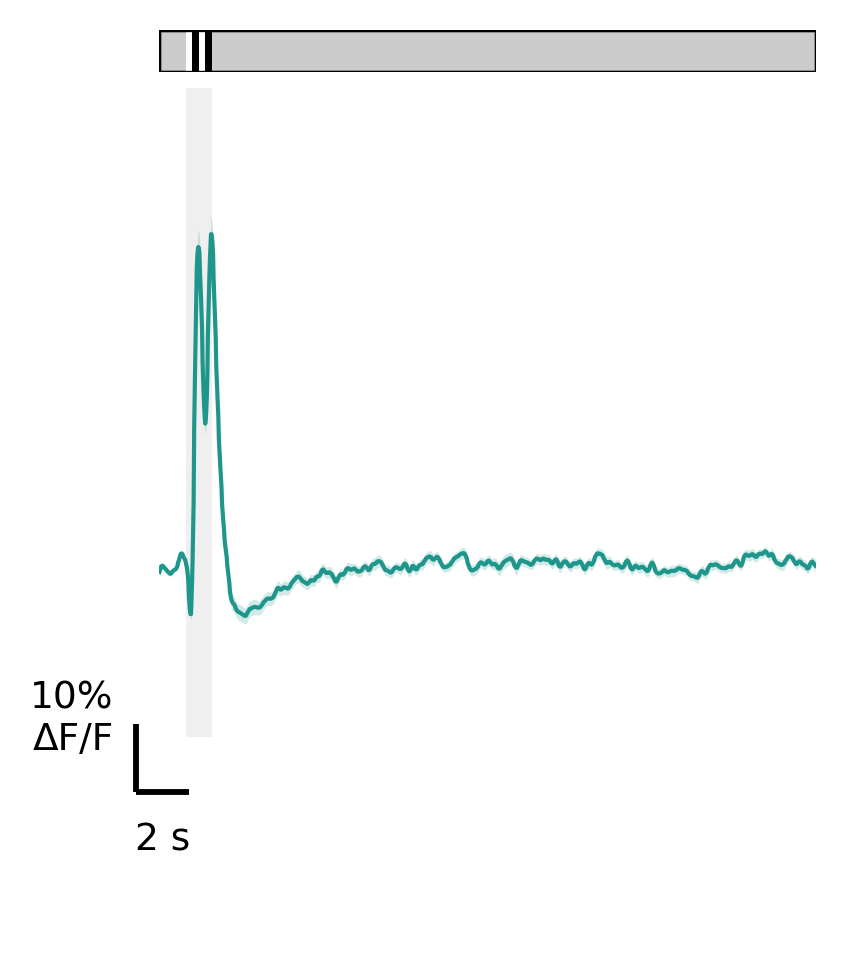

In [43]:
plot_csv_genotypes_overlay_stimstyle(
    files_df,
    sensor="ca",
    stim_time=0.99,
    genotype_order=["CTR"],
    subfolder_order=["M9"],
    colors=genotype_compartment_colors,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    figsize=(3, 4),
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    xlim=(0, 25),
    ylim=(-0.25, 0.7),
    df_over_f_scale=0.10,
    time_scale=2,
    line_width=1.0,
    sem_alpha=0.20,
    show_sem=True,
    show_legend=False,
)

## 6b. One panel per stimulus duration

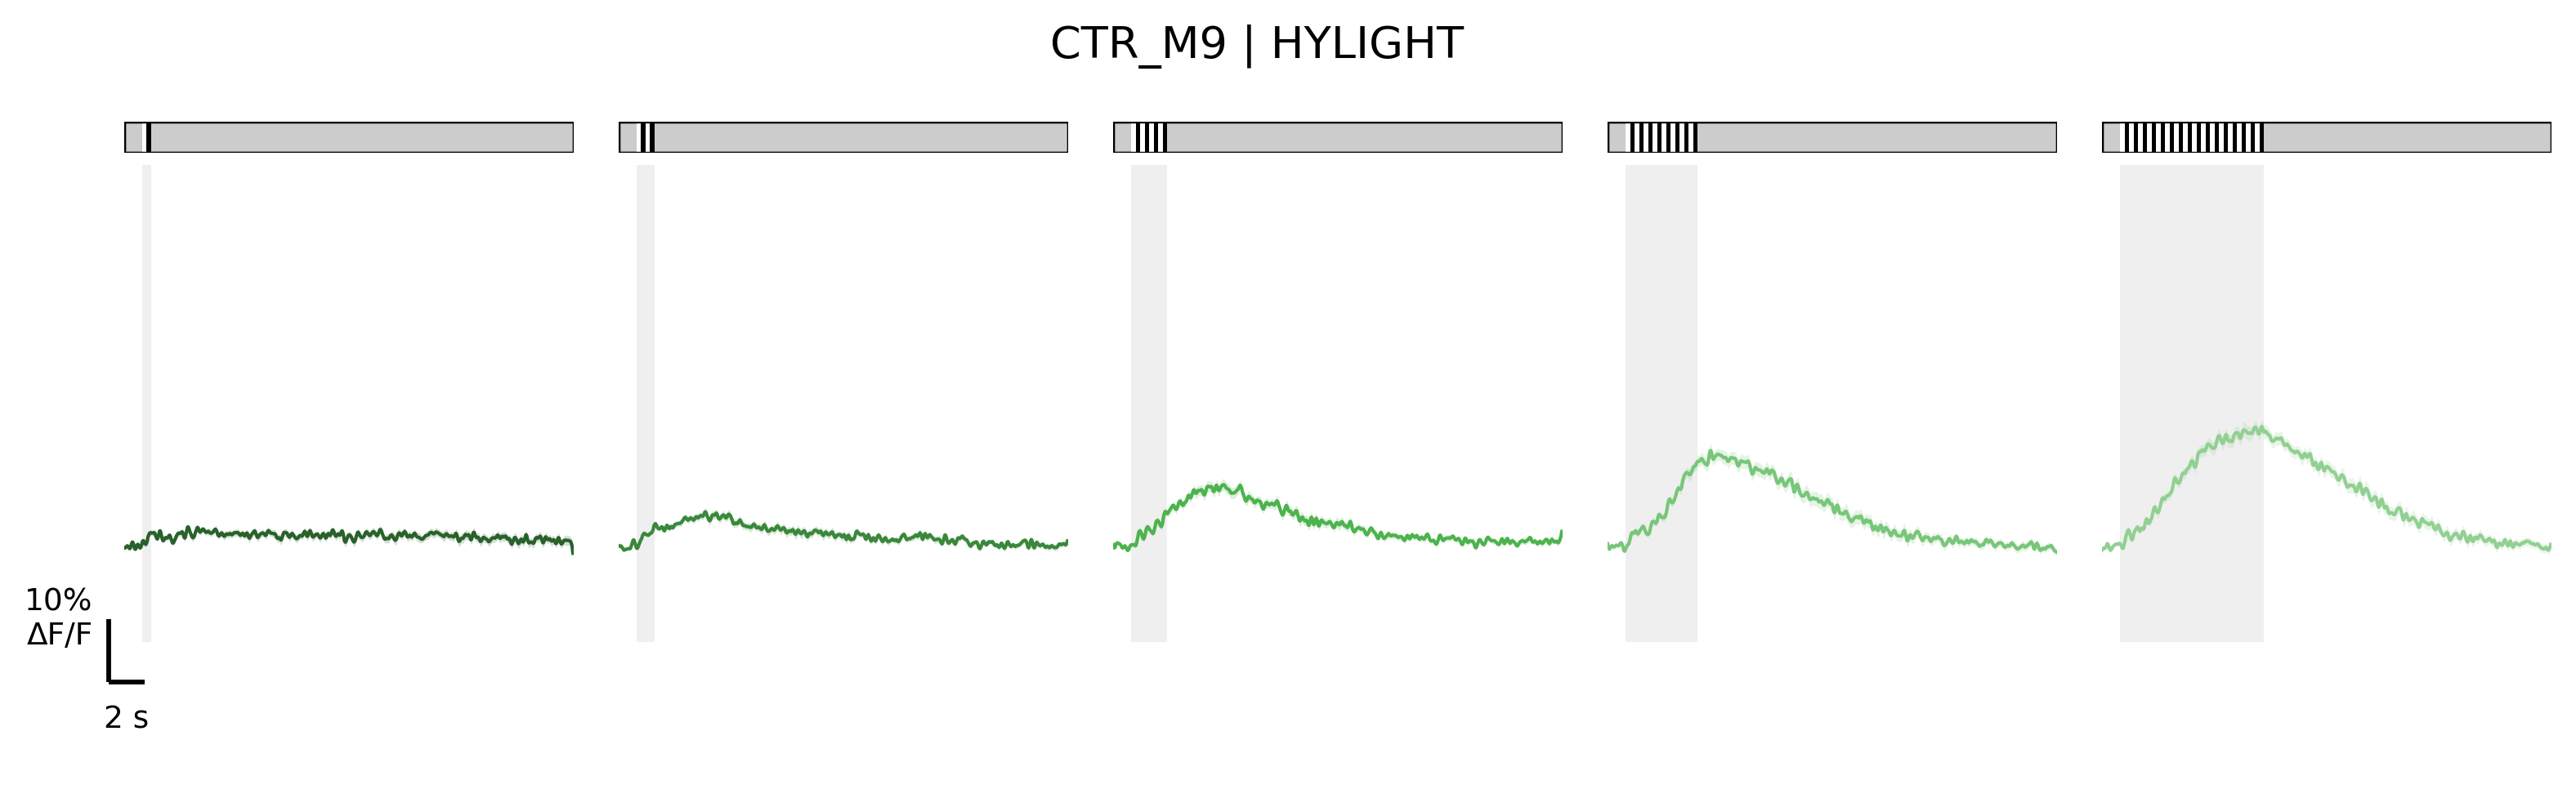

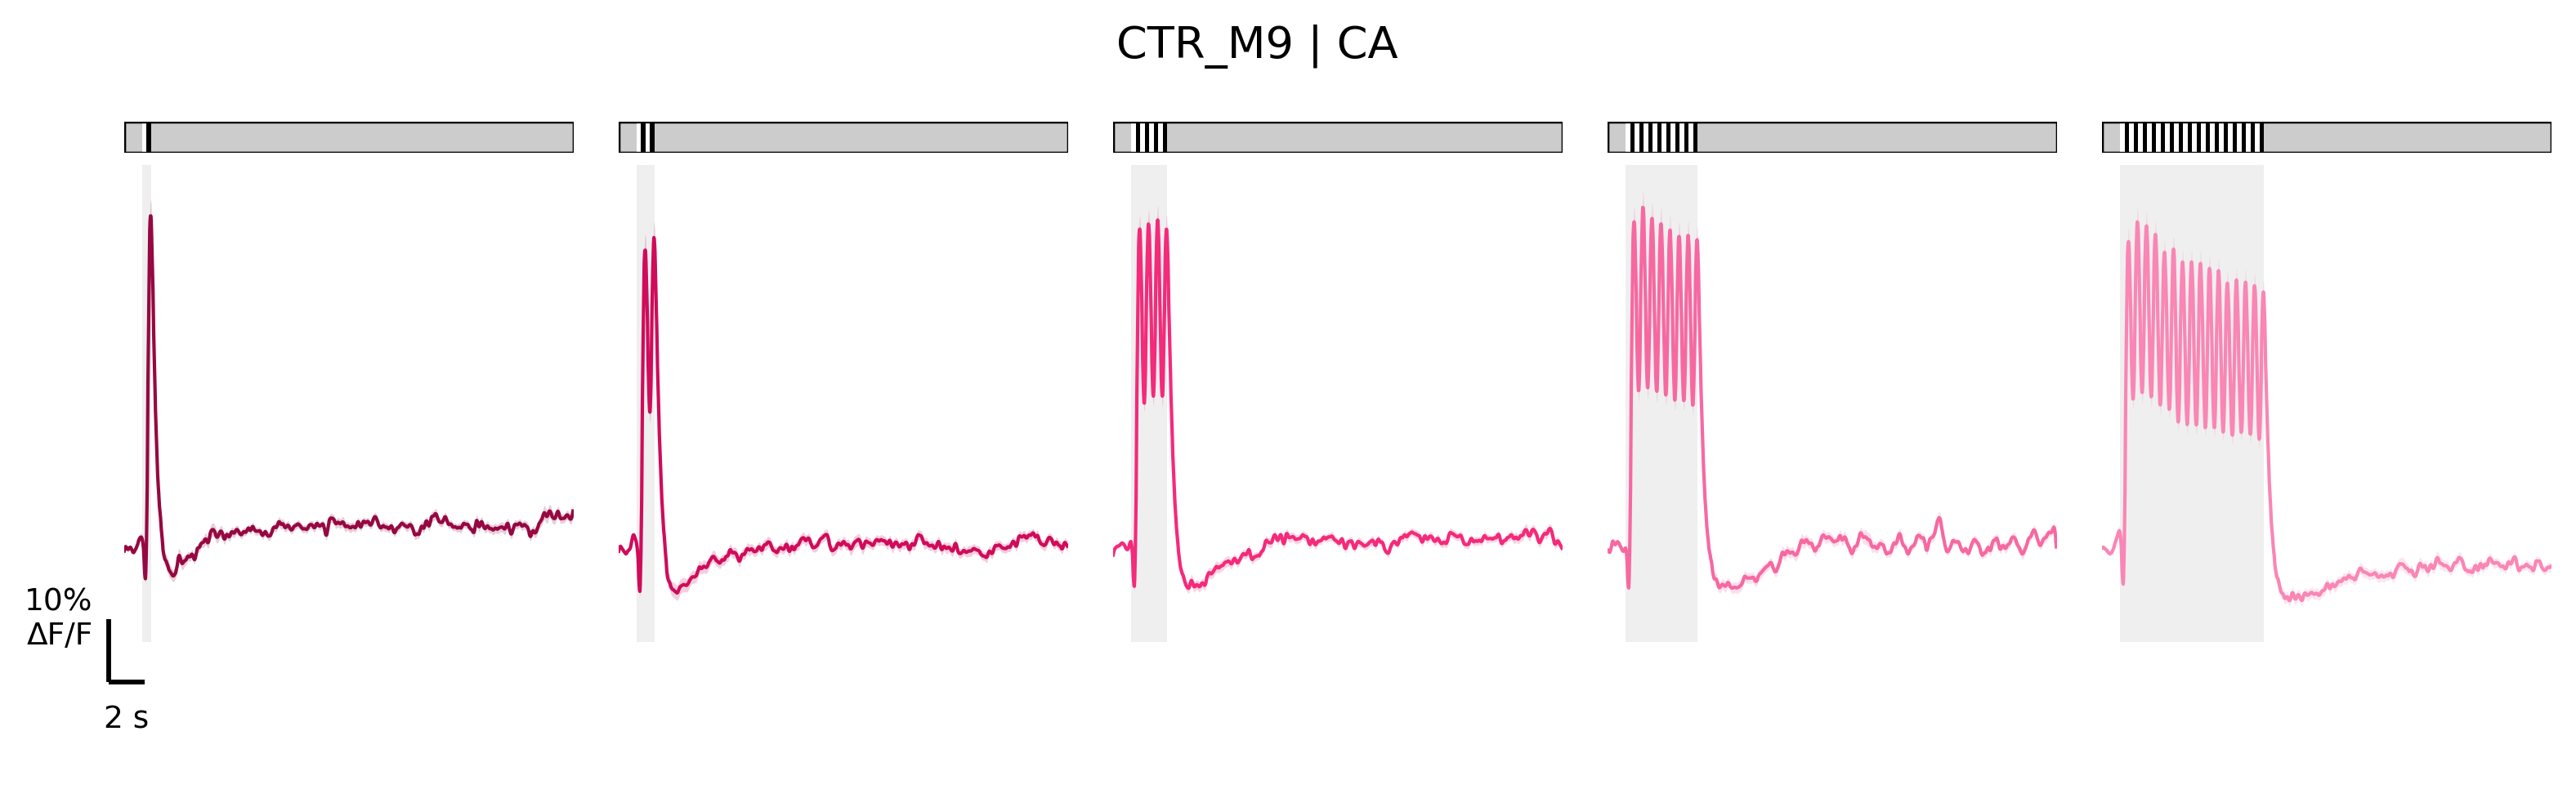

In [45]:
fig, axes = plot_csv_stim_duration_panels_stimcolors(
    files_df,
    sensor="hylight",
    genotype_order=("CTR",),
    
    subfolder_order=("M9",),
    stim_colors=stim_colors_hylight,
    stim_color_round_to=0.5,
    ylim=(-0.15, 0.6),
    xlim=(0, 25),
    apply_smoothing=True,
    smooth_wid=2,
    wspace=0.1,
    df_over_f_scale=0.1,
)

fig, axes = plot_csv_stim_duration_panels_stimcolors(
    files_df,
    sensor="ca",
    genotype_order=("CTR",),
    
    subfolder_order=("M9",),
    stim_colors=stim_colors_ca,
    stim_color_round_to=0.5,
    ylim=(-0.15, 0.6),
    xlim=(0, 25),
    apply_smoothing=True,
    smooth_wid=2,
    wspace=0.1
)



## 6c. All stimulus durations overlaid

Auto-detected stimulus times: [0.49, 0.99, 1.99, 3.99, 7.99]


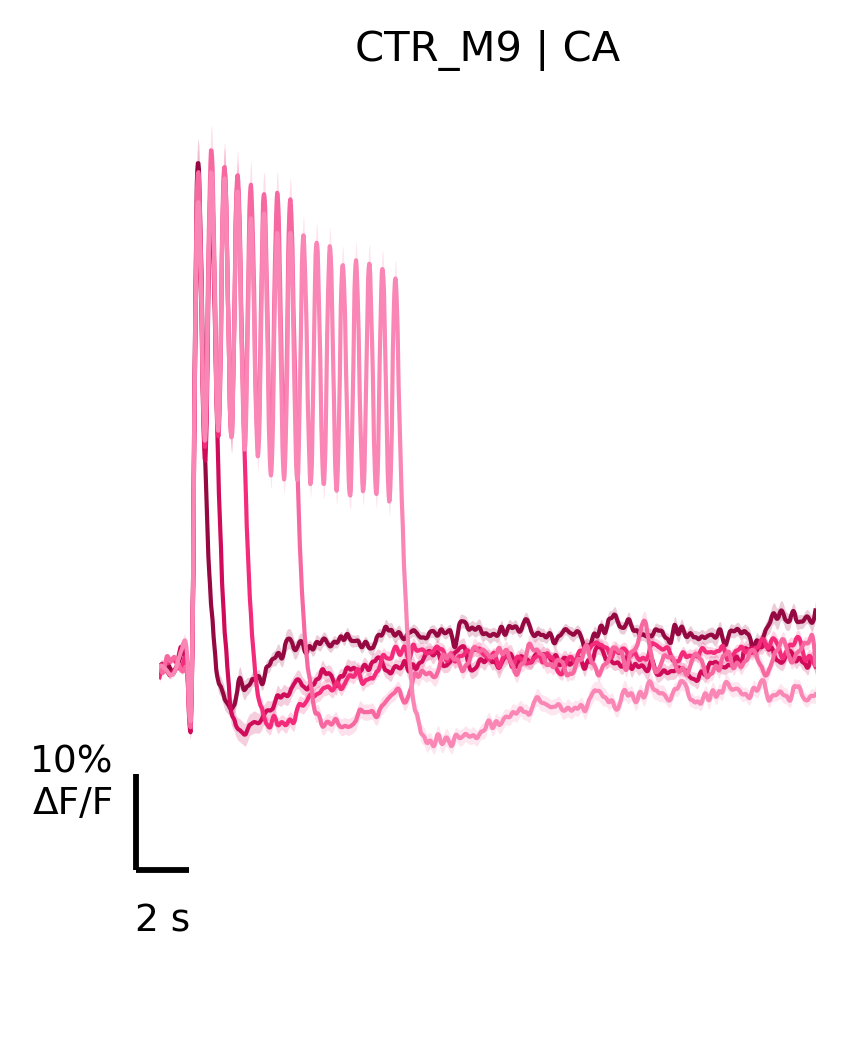

Auto-detected stimulus times: [0.49, 0.99, 1.99, 3.99, 7.99]


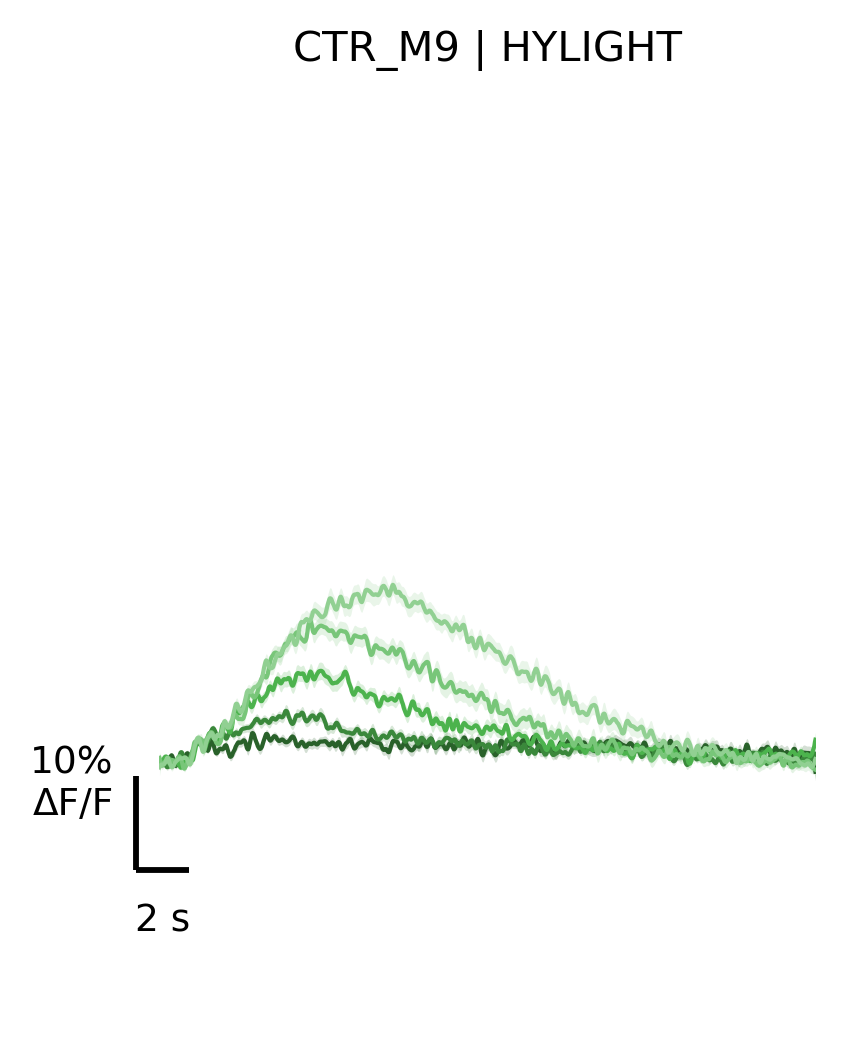

In [46]:
fig, ax = plot_csv_stimtimes_overlay(
    files_df,
    sensor="ca",
    genotype="CTR",
    subfolder="M9",
    stim_colors=stim_colors_ca,
    stim_color_round_to=0.5,
    xlim=(0, 25),
    ylim=(-0.15, 0.6),
    apply_smoothing=True,
    smooth_wid=2,
    show_axis_lines=False,
    show_legend=False,
)

fig, ax = plot_csv_stimtimes_overlay(
    files_df,
    sensor="hylight",
    genotype="CTR",
    subfolder="M9",
    stim_colors=stim_colors_hylight,
    stim_color_round_to=0.5,
    xlim=(0, 25),
    ylim=(-0.05, 0.72),
    apply_smoothing=True,
    smooth_wid=2,
    show_axis_lines=False,
    show_legend=False,
)

## 6d. HyLight 920/800 ratio and Ca of the same flies, all durations overlaid
`hylight920800ratio` (from `hylight` traces) and `hylight2920800ratio` (from `hylight2` traces) are the HyLight 920/800 ratios (ΔR/R) made by the `hylight920800_ratio` notebook; set `RATIO_SENSOR` to the one to plot. `ratio_flies_df` keeps only the recordings (fly, compartment, duration) that have a ratio recording, so the Ca plot shows the same flies as the ratio plot. Where the HyLight and Hy800 recordings had different numbers of neurons, the ratio uses only the first neurons of the larger one, while the Ca plot shows all neurons of those flies.

In [47]:
RATIO_SENSOR = "hylight920800ratio"   # or "hylight2920800ratio" for hylight2 recordings

ratio_flies_df = restrict_to_flies_with(files_df, RATIO_SENSOR)
summarize_files_df(ratio_flies_df)

,genotype,subfolder,sensor,stim_time,n_flies,n_neurons,missing_frequency
0,CTR,M9,ca,0.49,6,22,0
1,CTR,M9,ca,0.99,6,22,0
2,CTR,M9,ca,1.99,6,22,0
3,CTR,M9,ca,3.99,6,22,0
4,CTR,M9,ca,7.99,6,22,0
5,CTR,M9,hylight,0.49,6,22,0
6,CTR,M9,hylight,0.99,6,22,0
7,CTR,M9,hylight,1.99,6,22,0
8,CTR,M9,hylight,3.99,6,22,0
9,CTR,M9,hylight,7.99,6,22,0


Auto-detected stimulus times: [0.49, 0.99, 1.99, 3.99, 7.99]


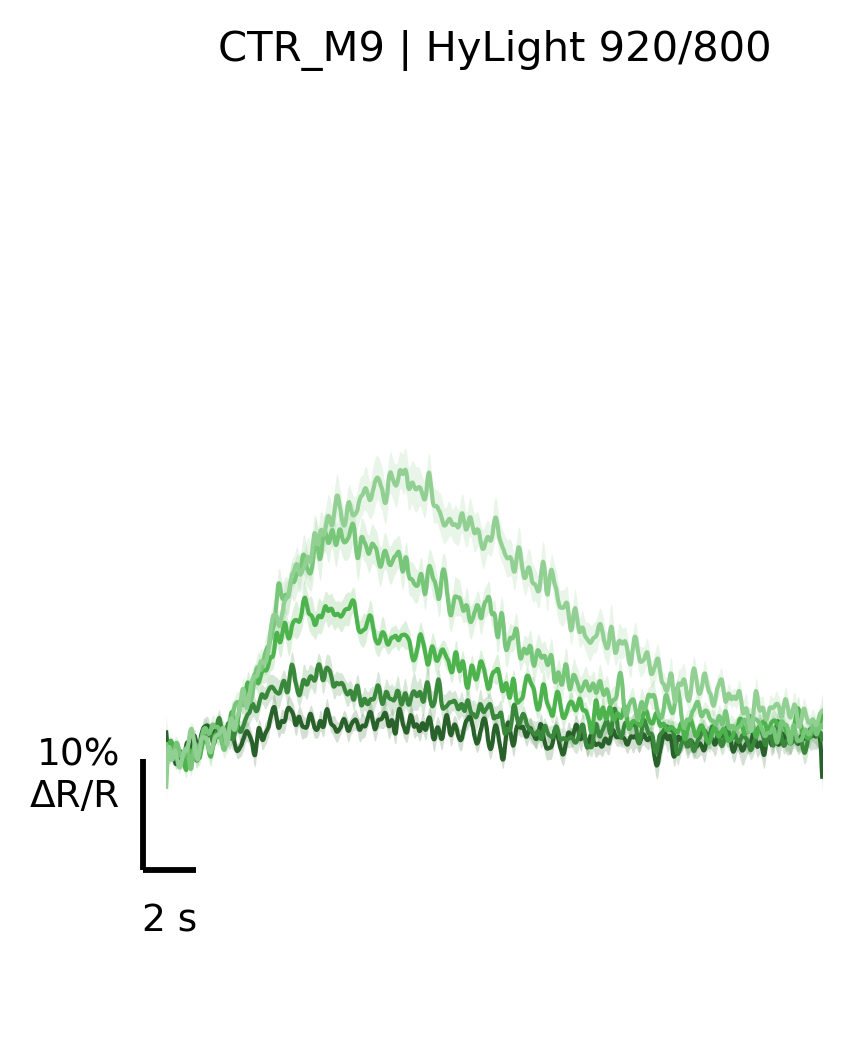

In [48]:
fig, ax = plot_csv_stimtimes_overlay(
    ratio_flies_df,
    sensor=RATIO_SENSOR,
    genotype="CTR",
    subfolder="M9",
    title="CTR_M9 | HyLight 920/800",
    stim_colors=stim_colors_hylight,
    stim_color_round_to=0.5,
    ylim=(-0.05, 0.6),
    xlim=(0, 25),
    smooth_wid=2,
    scale_unit="ΔR/R",
    show_axis_lines=False,
    show_legend=False,
)

Auto-detected stimulus times: [0.49, 0.99, 1.99, 3.99, 7.99]


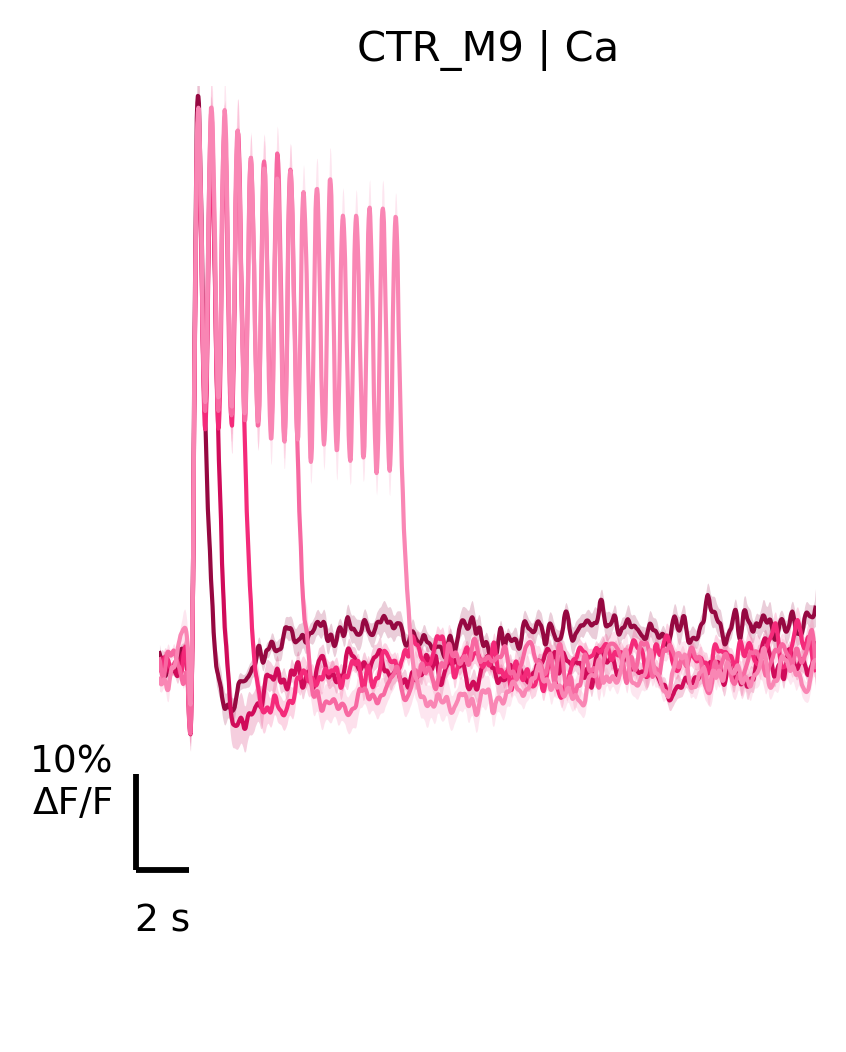

In [49]:
fig, ax = plot_csv_stimtimes_overlay(
    ratio_flies_df,
    sensor="ca",
    genotype="CTR",
    subfolder="M9",
    title="CTR_M9 | Ca",
    stim_colors=stim_colors_ca,
    stim_color_round_to=0.5,
    ylim=(-0.15, 0.6),
    xlim=(0, 25),
    smooth_wid=2,
    show_axis_lines=False,
    show_legend=False,
)